# Modelo baseline CNN para la predicción de RUL en FD001

Datos procesados en `EDA.ipynb`.

El modelo se entrena con los motores de `fd001_train.csv` y en cada época se mide el RMSE en los motores de validación (`fd001_val.csv`), separados en el EDA.

## 1. Librerías y configuración

In [85]:
import json
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

In [ ]:
DATA_DIR = Path("data/CMaps/training")
RESULTS_DIR = Path("results/cnn_baseline")
LSTM_BASELINE_RESULTS = Path("results/lstm_baseline/results.json")

SEED = 40

WINDOW_SIZE = 30
RUL_CAP = 125

N_FILTERS = 32
KERNEL_SIZE = 9
NUM_CONV_LAYERS = 3
DROPOUT = 0.35

LEARNING_RATE = 0.0001099433
BATCH_SIZE = 32

EPOCHS = 100
PATIENCE = 25

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo: {device}")

Dispositivo: cuda


In [87]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(SEED)

## 2. Carga de datos

In [88]:
train_df = pd.read_csv(DATA_DIR / "fd001_train.csv")
val_df = pd.read_csv(DATA_DIR / "fd001_val.csv")
test_df = pd.read_csv(DATA_DIR / "fd001_test.csv")

feature_cols = [
    col for col in train_df.columns if col not in ["engine_id", "time_in_cycles", "RUL"]
]

print(f"Train: {train_df.shape} ({train_df['engine_id'].nunique()} motores)")
print(f"Validación: {val_df.shape} ({val_df['engine_id'].nunique()} motores)")
print(f"Test: {test_df.shape} ({test_df['engine_id'].nunique()} motores)")
print(f"Variables ({len(feature_cols)}): {feature_cols}")

Train: (16561, 16) (80 motores)
Validación: (4070, 16) (20 motores)
Test: (13096, 16) (100 motores)
Variables (13): ['T24', 'T30', 'T50', 'P30', 'Nf', 'Nc', 'Ps30', 'phi', 'NRf', 'BPR', 'htBleed', 'W31', 'W32']


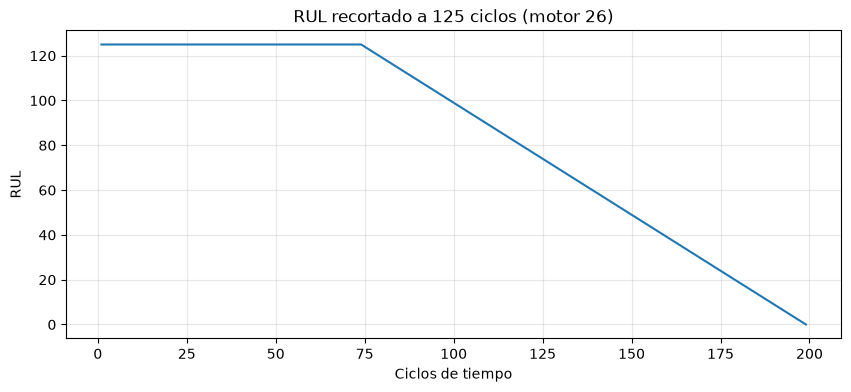

In [89]:
train_df["RUL"] = train_df["RUL"].clip(upper=RUL_CAP)
val_df["RUL"] = val_df["RUL"].clip(upper=RUL_CAP)
test_df["RUL"] = test_df["RUL"].clip(upper=RUL_CAP)

assert 56 in train_df["engine_id"].values
engine_1 = train_df[train_df["engine_id"] == 26]
plt.figure(figsize=(10, 4))
plt.plot(engine_1["time_in_cycles"], engine_1["RUL"])
plt.title(f"RUL recortado a {RUL_CAP} ciclos (motor 26)")
plt.xlabel("Ciclos de tiempo")
plt.ylabel("RUL")
plt.grid(alpha=0.3)
plt.show()

## 3. Ventanas temporales

In [90]:
min_test_length = test_df.groupby("engine_id").size().min()
print(f"Trayectoria de test más corta: {min_test_length} ciclos")

Trayectoria de test más corta: 31 ciclos


In [91]:
def create_train_windows(df, feature_cols, window_size):
    windows, targets = [], []
    for _, engine_data in df.groupby("engine_id"):
        features = engine_data[feature_cols].to_numpy()
        rul = engine_data["RUL"].to_numpy()
        for end in range(window_size, len(engine_data) + 1):
            windows.append(features[end - window_size : end])
            targets.append(rul[end - 1])
    return np.array(windows), np.array(targets)


def create_test_windows(df, feature_cols, window_size):
    windows, targets = [], []
    for _, engine_data in df.groupby("engine_id"):
        windows.append(engine_data[feature_cols].to_numpy()[-window_size:])
        targets.append(engine_data["RUL"].iloc[-1])
    return np.array(windows), np.array(targets)


X_train, y_train = create_train_windows(train_df, feature_cols, WINDOW_SIZE)
X_val, y_val = create_train_windows(val_df, feature_cols, WINDOW_SIZE)
X_test, y_test = create_test_windows(test_df, feature_cols, WINDOW_SIZE)

print(f"X_train: {X_train.shape} | y_train: {y_train.shape}")
print(f"X_val:   {X_val.shape} | y_val:   {y_val.shape}")
print(f"X_test:  {X_test.shape} | y_test:  {y_test.shape}")

X_train: (14241, 30, 13) | y_train: (14241,)
X_val:   (3490, 30, 13) | y_val:   (3490,)
X_test:  (100, 30, 13) | y_test:  (100,)


In [92]:
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
# Objetivo escalado a [0, 1]
y_train_tensor = torch.tensor(y_train / RUL_CAP, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)

train_loader = DataLoader(
    TensorDataset(X_train_tensor, y_train_tensor),
    batch_size=BATCH_SIZE,
    shuffle=True,
)

# 4. Modelo

In [93]:
class CNNModel(nn.Module):
    def __init__(
        self, n_features, window_size, n_filters, kernel_size, num_conv_layers, dropout
    ):
        super().__init__()
        layers = []
        in_channels = n_features
        for _ in range(num_conv_layers):
            layers += [
                nn.Conv1d(in_channels, n_filters, kernel_size, padding="same"),
                nn.ReLU(),
            ]
            in_channels = n_filters
        self.conv = nn.Sequential(*layers)
        self.dropout = nn.Dropout(dropout)
        self.output_layer = nn.Linear(n_filters * window_size, 1)

    def forward(self, x):
        # (lote, ciclos, variables) -> (lote, variables, ciclos)
        x = x.permute(0, 2, 1)
        x = self.conv(x)
        x = x.flatten(start_dim=1)
        return self.output_layer(self.dropout(x)).squeeze(-1)


model = CNNModel(
    n_features=len(feature_cols),
    window_size=WINDOW_SIZE,
    n_filters=N_FILTERS,
    kernel_size=KERNEL_SIZE,
    num_conv_layers=NUM_CONV_LAYERS,
    dropout=DROPOUT,
).to(device)

print(model)

CNNModel(
  (conv): Sequential(
    (0): Conv1d(13, 32, kernel_size=(9,), stride=(1,), padding=same)
    (1): ReLU()
    (2): Conv1d(32, 32, kernel_size=(9,), stride=(1,), padding=same)
    (3): ReLU()
    (4): Conv1d(32, 32, kernel_size=(9,), stride=(1,), padding=same)
    (5): ReLU()
  )
  (dropout): Dropout(p=0.35, inplace=False)
  (output_layer): Linear(in_features=960, out_features=1, bias=True)
)


In [ ]:
from torchinfo import summary

summary(model, input_size=(BATCH_SIZE, WINDOW_SIZE, len(feature_cols)))

Layer (type:depth-idx)                   Output Shape              Param #
CNNModel                                 [32]                      --
├─Sequential: 1-1                        [32, 32, 30]              --
│    └─Conv1d: 2-1                       [32, 32, 30]              3,776
│    └─ReLU: 2-2                         [32, 32, 30]              --
│    └─Conv1d: 2-3                       [32, 32, 30]              9,248
│    └─ReLU: 2-4                         [32, 32, 30]              --
│    └─Conv1d: 2-5                       [32, 32, 30]              9,248
│    └─ReLU: 2-6                         [32, 32, 30]              --
├─Dropout: 1-2                           [32, 960]                 --
├─Linear: 1-3                            [32, 1]                   961
Total params: 23,233
Trainable params: 23,233
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 21.41
Input size (MB): 0.05
Forward/backward pass size (MB): 0.74
Params size (MB): 0.09
Estimated Total Size 

## 5. Entrenamiento

In [95]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

train_rmse_history = []
val_rmse_history = []

best_val_rmse = float("inf")
best_val_epoch = 0
best_state = None

for epoch in range(1, EPOCHS + 1):
    model.train()
    epoch_loss = 0.0

    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        optimizer.zero_grad()
        loss = criterion(model(X_batch), y_batch)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item() * len(X_batch)

    # Se desescala para expresar el RMSE en ciclos
    epoch_rmse = np.sqrt(epoch_loss / len(train_loader.dataset)) * RUL_CAP
    train_rmse_history.append(epoch_rmse)

    model.eval()
    with torch.no_grad():
        y_val_pred = model(X_val_tensor.to(device)).cpu().numpy() * RUL_CAP
    val_rmse = np.sqrt(np.mean((y_val_pred - y_val) ** 2))
    val_rmse_history.append(val_rmse)

    # Copia de los pesos de la mejor época hasta el momento
    if val_rmse < best_val_rmse:
        best_val_rmse = val_rmse
        best_val_epoch = epoch
        best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}

    if epoch == 1 or epoch % 5 == 0:
        print(
            f"Época {epoch:3d}/{EPOCHS} | RMSE entrenamiento: {epoch_rmse:.2f} | RMSE validación: {val_rmse:.2f}"
        )

    if epoch - best_val_epoch >= PATIENCE:
        print(
            f"Early stopping en la época {epoch}: {PATIENCE} épocas sin mejorar en validación"
        )
        break

stopped_epoch = epoch
model.load_state_dict(best_state)
print(
    f"Se cargan los pesos de la época {best_val_epoch} (RMSE validación: {best_val_rmse:.2f})"
)

Época   1/100 | RMSE entrenamiento: 33.01 | RMSE validación: 19.09
Época   5/100 | RMSE entrenamiento: 17.39 | RMSE validación: 14.54
Época  10/100 | RMSE entrenamiento: 15.32 | RMSE validación: 14.34
Época  15/100 | RMSE entrenamiento: 14.74 | RMSE validación: 13.64
Época  20/100 | RMSE entrenamiento: 14.14 | RMSE validación: 14.78
Época  25/100 | RMSE entrenamiento: 13.77 | RMSE validación: 12.45
Época  30/100 | RMSE entrenamiento: 13.33 | RMSE validación: 13.48
Época  35/100 | RMSE entrenamiento: 13.01 | RMSE validación: 14.66
Época  40/100 | RMSE entrenamiento: 12.46 | RMSE validación: 13.39
Early stopping en la época 44: 25 épocas sin mejorar en validación
Se cargan los pesos de la época 19 (RMSE validación: 12.08)


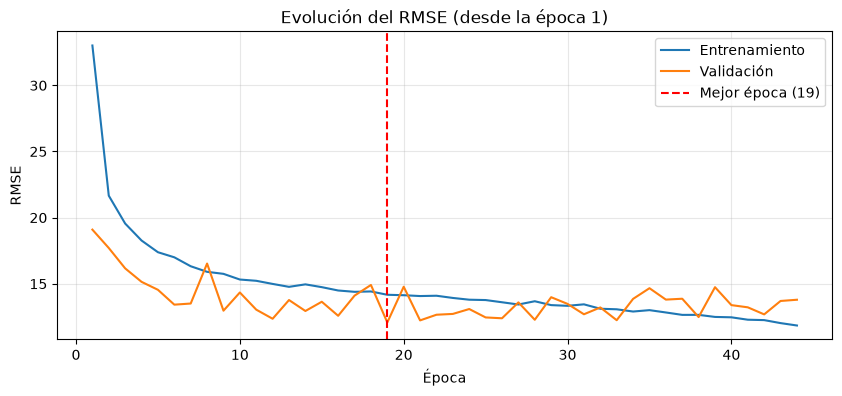

In [96]:
START_EPOCH = 1
epochs_range = range(START_EPOCH, stopped_epoch + 1)

plt.figure(figsize=(10, 4))
plt.plot(epochs_range, train_rmse_history[START_EPOCH - 1 :], label="Entrenamiento")
plt.plot(epochs_range, val_rmse_history[START_EPOCH - 1 :], label="Validación")
plt.axvline(
    best_val_epoch, color="red", linestyle="--", label=f"Mejor época ({best_val_epoch})"
)
plt.title(f"Evolución del RMSE (desde la época {START_EPOCH})")
plt.xlabel("Época")
plt.ylabel("RMSE")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 6. Evaluación en test

In [97]:
def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_pred - y_true) ** 2))


def phm08_score(y_true, y_pred):
    errors = y_pred - y_true
    penalties = np.where(errors < 0, np.exp(-errors / 13) - 1, np.exp(errors / 10) - 1)
    return np.sum(penalties)


model.eval()
with torch.no_grad():
    y_pred = model(X_test_tensor.to(device)).cpu().numpy() * RUL_CAP

test_rmse = rmse(y_test, y_pred)
test_score = phm08_score(y_test, y_pred)

print(f"RMSE test:   {test_rmse:.2f}")
print(f"Score PHM08: {test_score:.2f}")

RMSE test:   13.45
Score PHM08: 293.17


Comparación entre el RUL real y el predicho para cada motor de test, ordenados de menor a mayor RUL real.

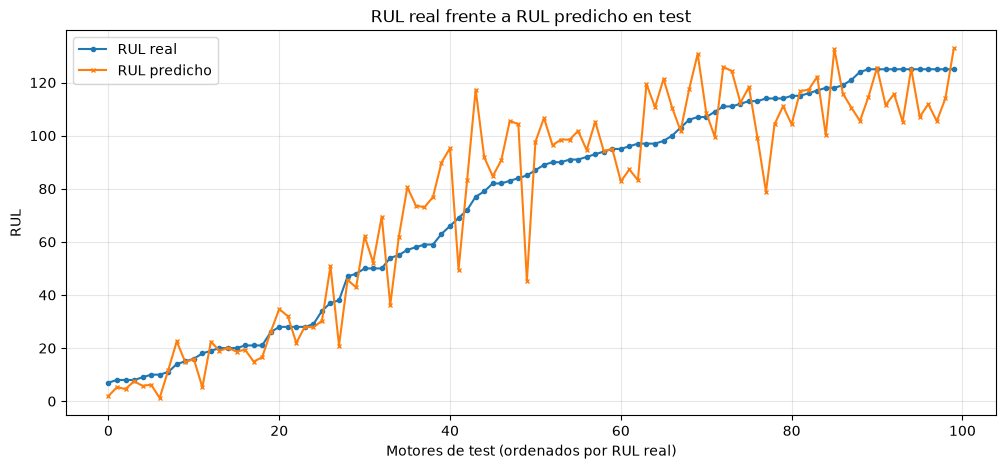

In [98]:
order = np.argsort(y_test)

plt.figure(figsize=(12, 5))
plt.plot(y_test[order], label="RUL real", marker="o", markersize=3)
plt.plot(y_pred[order], label="RUL predicho", marker="x", markersize=3)
plt.title("RUL real frente a RUL predicho en test")
plt.xlabel("Motores de test (ordenados por RUL real)")
plt.ylabel("RUL")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

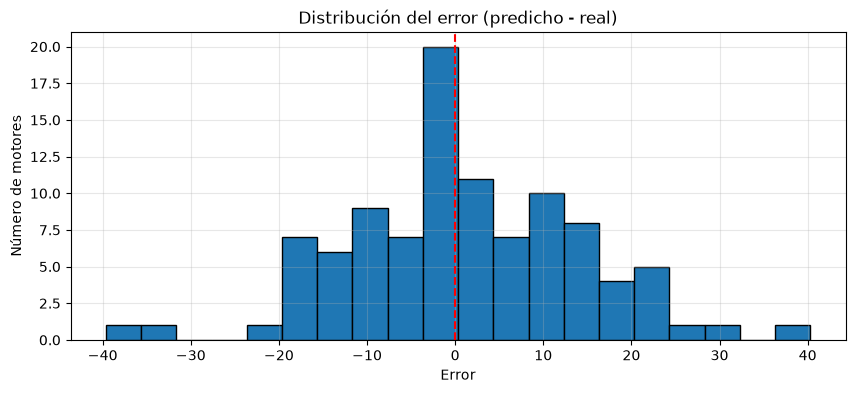

Predicciones tardías (error > 0):   53
Predicciones tempranas (error < 0): 47


In [99]:
errors = y_pred - y_test

plt.figure(figsize=(10, 4))
plt.hist(errors, bins=20, edgecolor="black")
plt.axvline(0, color="red", linestyle="--")
plt.title("Distribución del error (predicho - real)")
plt.xlabel("Error")
plt.ylabel("Número de motores")
plt.grid(alpha=0.3)
plt.show()

print(f"Predicciones tardías (error > 0):   {(errors > 0).sum()}")
print(f"Predicciones tempranas (error < 0): {(errors < 0).sum()}")

### Evolución del RUL predicho a lo largo de la vida de un motor


In [100]:
def predict_engine_trajectory(model, engine_data, feature_cols, window_size):
    X_engine, y_engine = create_train_windows(engine_data, feature_cols, window_size)
    model.eval()
    with torch.no_grad():
        y_engine_pred = (
            # Se desescala para expresar el RUL en ciclos
            model(torch.tensor(X_engine, dtype=torch.float32).to(device)).cpu().numpy()
            * RUL_CAP
        )
    return y_engine, y_engine_pred


def plot_engine_trajectory(model, df, engine_id, set_name):
    available = sorted(df["engine_id"].unique().tolist())
    assert engine_id in available, (
        f"El motor {engine_id} no está en {set_name}. Disponibles: {available}"
    )

    engine_data = df[df["engine_id"] == engine_id]
    cycles = engine_data["time_in_cycles"].to_numpy()
    y_engine, y_engine_pred = predict_engine_trajectory(
        model, engine_data, feature_cols, WINDOW_SIZE
    )

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.axvspan(0, cycles[WINDOW_SIZE - 1], color="lightgray", alpha=0.4, linewidth=0)
    ax.plot(
        cycles,
        engine_data["RUL"],
        color="dimgray",
        linestyle="--",
        linewidth=2,
        label="RUL real",
    )
    ax.plot(
        cycles[WINDOW_SIZE - 1 :],
        y_engine_pred,
        color="tab:blue",
        linewidth=2,
        label="RUL predicho",
    )

    ax.set_title(
        f"{set_name} - motor {engine_id} ({len(engine_data)} ciclos) | "
        f"RMSE: {rmse(y_engine, y_engine_pred):.1f} ciclos"
    )
    ax.set_xlabel("Ciclo")
    ax.set_ylabel("RUL")
    # Mismo eje en todos los motores para que los errores se puedan comparar
    ax.set_xlim(0, cycles[-1])
    ax.set_ylim(0, RUL_CAP + 10)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(alpha=0.3)
    ax.legend(frameon=False)
    plt.show()


print(f"Motores de validación: {sorted(val_df['engine_id'].unique().tolist())}")
print(f"Motores de test: {test_df['engine_id'].min()} a {test_df['engine_id'].max()}")

Motores de validación: [1, 5, 11, 13, 19, 23, 31, 32, 34, 40, 45, 46, 54, 71, 74, 77, 78, 81, 84, 91]
Motores de test: 1 a 100


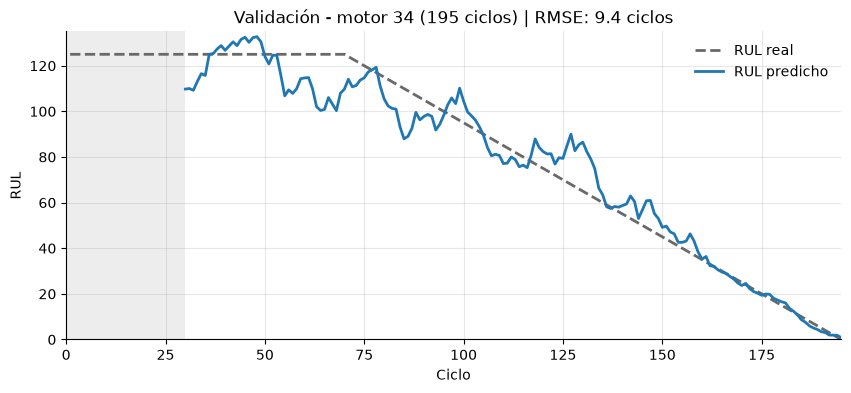

In [101]:
VAL_ENGINE = 34

plot_engine_trajectory(model, val_df, VAL_ENGINE, "Validación")

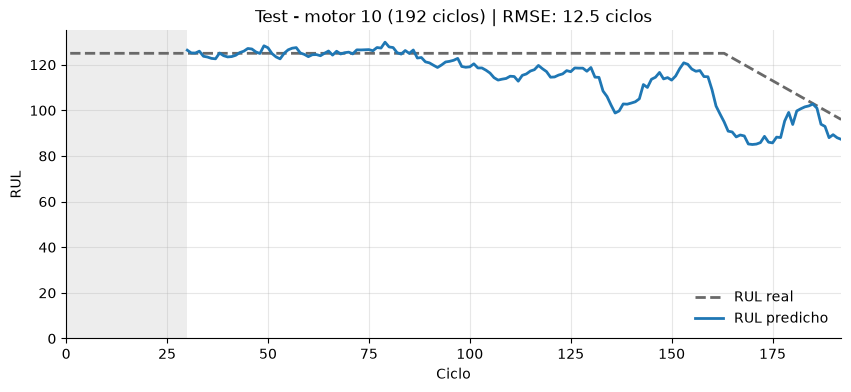

In [102]:
TEST_ENGINE = 10

plot_engine_trajectory(model, test_df, TEST_ENGINE, "Test")

## 7. Guardado de resultados

In [103]:
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

torch.save(model.state_dict(), RESULTS_DIR / "cnn_baseline.pt")

results = {
    "hyperparameters": {
        "seed": SEED,
        "window_size": WINDOW_SIZE,
        "rul_cap": RUL_CAP,
        "n_filters": N_FILTERS,
        "kernel_size": KERNEL_SIZE,
        "num_conv_layers": NUM_CONV_LAYERS,
        "dropout": DROPOUT,
        "learning_rate": LEARNING_RATE,
        "batch_size": BATCH_SIZE,
        "max_epochs": EPOCHS,
        "patience": PATIENCE,
    },
    "n_features": len(feature_cols),
    "trainable_parameters": sum(p.numel() for p in model.parameters()),
    "metrics": {
        "best_epoch_train_rmse": float(train_rmse_history[best_val_epoch - 1]),
        "stopped_epoch": stopped_epoch,
        "best_val_epoch": best_val_epoch,
        "best_val_rmse": float(best_val_rmse),
        "test_rmse": float(test_rmse),
        "test_phm08_score": float(test_score),
    },
}

with open(RESULTS_DIR / "results.json", "w") as file:
    json.dump(results, file, indent=4)

print(json.dumps(results, indent=4))

{
    "hyperparameters": {
        "seed": 40,
        "window_size": 30,
        "rul_cap": 125,
        "n_filters": 32,
        "kernel_size": 9,
        "num_conv_layers": 3,
        "dropout": 0.35,
        "learning_rate": 0.0001099433,
        "batch_size": 32,
        "max_epochs": 100,
        "patience": 25
    },
    "n_features": 13,
    "trainable_parameters": 23233,
    "metrics": {
        "best_epoch_train_rmse": 14.167501264439293,
        "stopped_epoch": 44,
        "best_val_epoch": 19,
        "best_val_rmse": 12.07595932816638,
        "test_rmse": 13.452644301510256,
        "test_phm08_score": 293.17462388168263
    }
}


## 8. Comparación con el baseline LSTM

In [104]:
with open(LSTM_BASELINE_RESULTS) as file:
    lstm_results = json.load(file)

comparison = pd.DataFrame(
    {
        name: {
            "Parámetros": model_results["trainable_parameters"],
            "Mejor época": model_results["metrics"]["best_val_epoch"],
            "RMSE validación": model_results["metrics"]["best_val_rmse"],
            "RMSE test": model_results["metrics"]["test_rmse"],
            "Score PHM08": model_results["metrics"]["test_phm08_score"],
        }
        for name, model_results in [("LSTM", lstm_results), ("CNN", results)]
    }
)

display(comparison.round(2))

,LSTM,CNN
Parámetros,22945.00,23233.00
Mejor época,29.00,19.00
RMSE validación,11.66,12.08
RMSE test,13.37,13.45
Score PHM08,320.81,293.17
